# Single-cell quality control with coSMicQC

**Question:** can coSMicQC find the badly outlined cells in our profiles, so that we can remove them with a simple rule?

**Answer: not yet. coSMicQC runs well on our data, but we should not use it to remove cells from these profiles.**

These profiles come from the first CellProfiler settings, and notebook 01 showed that those settings cut many nuclei into pieces. We applied the rules of the coSMicQC paper to 4.38 million cells, and 22 to 31% of cells failed in each plate and cell line. Most failures are not the cells we want to remove:

- **Healthy-looking cells fail.** All cells in the second DNA peak of CL2 fail, and 34 to 80% of them fail in CL1. Condition 3 causes this.
- **Cut nuclei stay in the data.** Only 9 to 21% of objects with too little DNA fail. Cut nuclei fail less often than other nuclei.
- **Some rules help.** Conditions 1 and 2 did mark bad outlines in the example images. These two conditions need a second test on better data.

The likely cause is the data, not coSMicQC. In CL2, nearly half of the objects hold too little DNA, and these objects pull the average down. The limits then sit too low. We keep the marks in a separate file, and we remove no cells. We should run this notebook again after the new CellProfiler run.

## How to read this notebook

Each section follows the same pattern, as in `01.sc-profiles-qc-check.ipynb`:

- **What we check**: the question, in one line.
- **Why it matters**: what goes wrong later if we skip this check.
- **What good looks like**: the result we hope for.
- **What we found**: the result and what it means.

We explain *what* we check and *why*. We do not explain how each method works.

**Words used in this notebook**

| Word | Meaning |
|---|---|
| Profile | The table of measurements for one plate. It has one row per cell. |
| Segmentation | The step where CellProfiler draws an outline around each nucleus and cell. |
| Under-segmented | One outline holds two or more nuclei or cells. |
| Over-segmented | One nucleus or cell is cut into two or more outlines. |
| Outlier | A cell that coSMicQC marks as a possible bad outline. |
| Standard deviation (SD) | How far values usually sit from the average. |
| Z-score | The distance of a value from the average, in SDs. A z-score of 1.5 means 1.5 SDs above the average. |
| First DNA peak | Cells that have one full set of DNA (G1 phase). This is the largest group of cells. |
| Second DNA peak | Cells that copied their DNA, so they have two full sets (G2 phase). They are healthy cells. |
| CL1, CL2 | The two cell lines. Columns 1 to 12 hold CL1, and columns 13 to 24 hold CL2. |

## What coSMicQC does

coSMicQC is a Python package from the Cytomining group. It looks at a few measurements of each cell. It marks a cell as an outlier if the cell sits too far from the average of its group.

It only marks cells. It does not repair an outline, and it cannot bring back a nucleus that CellProfiler deleted. We keep every cell in the tables, and we save the marks in a separate file. Later steps can then choose what to do with them.

## The rules we use

We use the 3 conditions and 4 measurements from Figure 2 of the coSMicQC paper ([bioRxiv 10.1101/2025.10.14.682427](https://www.biorxiv.org/content/10.1101/2025.10.14.682427v2)).

| Condition | The problem it looks for | Measurement | Limit (z-score) |
|---|---|---|---|
| 1. Under-segmented nuclei | Two or more nuclei in one outline | Mass displacement: the distance between the centre of the outline and the centre of the DNA signal | Above 0.05 |
| | | **and** total DNA signal in the nucleus | Above 1.5 |
| 2. Poorly segmented nuclei | Debris, or a nucleus cut into pieces | Solidity: how smooth and round the outline is | Below -1.6 |
| 3. Under-segmented cells | One cell outline that holds the nuclei of other cells | Total DNA signal in the whole cell | Above 0.5 |

A cell fails condition 1 only if both of its measurements pass their limits. A cell **fails QC** if it fails at least one condition.

**A note on the limits.** Panel A of Figure 2 shows 1.15 and -1.16. The text of the paper says 1.5 and -1.6, and so do panels B and C of the same figure. The code from the authors also uses 1.5 and -1.6, in `docs/manuscripts/cosmicqc_paper_v1/figure_2`. So 1.15 and -1.16 appear to be typing errors, and we use 1.5 and -1.6. Section 9 shows what changes if we use the numbers in panel A.

**A note on the groups.** The authors calculated z-scores over one whole plate. We calculate them separately for each plate and each cell line, because our two cell lines have different normal shapes. Section 9 shows what changes if we use the whole plate.

## Setup

Paths and settings are here. This notebook reads only the columns it needs, so it needs much less memory than notebook 01. Run it with `_run-cosmic-qc.sbatch`, not on the login node.

In [1]:
import os
import pathlib

n_threads = 8
os.environ["POLARS_MAX_THREADS"] = str(n_threads)
os.environ["OMP_NUM_THREADS"] = str(n_threads)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
from cosmicqc import analyze
from PIL import Image
from scipy import ndimage as ndi

In [2]:
seed = 0

profiles_dir = pathlib.Path("../../data/sc-profiles").resolve(strict=True)
metadata_dir = profiles_dir / "metadata"
results_dir = pathlib.Path("../../../../results/PALS-screen-profiles").resolve(strict=True)
images_dir = pathlib.Path("../../../../project-data/PALS-screen-data").resolve(strict=True)

# notebook 01 saves the cut nuclei of 72 images here
qc_cache_dir = pathlib.Path("../../data/qc-cache").resolve()

# this notebook saves one file of marks per plate here
output_dir = pathlib.Path("../../data/cosmicqc").resolve()
output_dir.mkdir(parents=True, exist_ok=True)

# the 4 measurements, with the names CellProfiler uses in our tables
mass_displacement = "Nuclei_Intensity_MassDisplacement_CorrDNA"
nucleus_dna = "Nuclei_Intensity_IntegratedIntensity_CorrDNA"
nucleus_solidity = "Nuclei_AreaShape_Solidity"
cell_dna = "Cells_Intensity_IntegratedIntensity_CorrDNA"

# the rules of the paper: a positive limit marks high values, a negative limit marks low values
conditions = {
    "under_segmented_nuclei": {mass_displacement: 0.05, nucleus_dna: 1.5},
    "poorly_segmented_nuclei": {nucleus_solidity: -1.6},
    "under_segmented_cells": {cell_dna: 0.5},
}

# the same rules with the numbers printed in panel A of Figure 2
conditions_panel_a = {
    "under_segmented_nuclei": {mass_displacement: 0.05, nucleus_dna: 1.15},
    "poorly_segmented_nuclei": {nucleus_solidity: -1.16},
    "under_segmented_cells": {cell_dna: 0.5},
}

condition_names = list(conditions)
condition_titles = {
    "under_segmented_nuclei": "1. Under-segmented nuclei",
    "poorly_segmented_nuclei": "2. Poorly segmented nuclei",
    "under_segmented_cells": "3. Under-segmented cells",
}

# fixed order and colors: the same as in notebook 01
plate_order = ["1h", "4h", "24h"]
line_order = ["CL1", "CL2"]
line_colors = {"CL1": "#6250d6", "CL2": "#eda100"}
limit_color = "#d03b3b"
guide_color = "#52514e"



def in_time_order(table):
    """Sort a table by cell line, then by plate in time order."""
    order = pl.col("plate").replace_strict({time: i for i, time in enumerate(plate_order)}, return_dtype=pl.Int64)
    return table.sort("cell_line", order)


sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(-1)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_fmt_str_lengths(50)

polars.config.Config

## 1. Load the profiles

**What we check:** the profiles hold the 4 measurements, with no missing values.

**Why it matters:** coSMicQC calculates z-scores with a method that fails on missing values. One empty value in a column gives no result for the whole column, and no error message.

**What good looks like:** 3 plates, one row per cell, and no missing values in the 4 measurements.

In [3]:
plate_files = {path.stem.split("_")[3]: path for path in sorted(profiles_dir.glob("*.parquet"))}
plate_names = {time: plate_files[time].stem for time in plate_order}

columns = [
    "Metadata_Plate",
    "Metadata_Well",
    "Metadata_Site",
    "Metadata_Acquisition",
    "Metadata_ObjectNumber",
    "Nuclei_AreaShape_Area",
    "Nuclei_Location_Center_X",
    "Nuclei_Location_Center_Y",
    mass_displacement,
    nucleus_dna,
    nucleus_solidity,
    cell_dna,
]

platemap = pl.read_csv(metadata_dir / "platemap.csv", infer_schema_length=0).select(
    pl.col("Well").alias("Metadata_Well"),
    pl.col("Compound ID").alias("compound"),
)
ligands = (
    pl.read_csv(metadata_dir / "ligands.csv", infer_schema_length=0)
    .select(pl.col("destination well").alias("well"), pl.col("Treatment").alias("ligand"))
    .filter(pl.col("well").is_not_null())
    .with_columns((pl.col("well").str.slice(0, 1) + pl.col("well").str.slice(1).str.zfill(2)).alias("Metadata_Well"))
    .drop("well")
)
wells = (
    platemap.join(ligands, on="Metadata_Well", how="left")
    .with_columns(
        pl.col("Metadata_Well").str.slice(0, 1).alias("row"),
        pl.col("Metadata_Well").str.slice(1).cast(pl.Int64).alias("column"),
    )
    .with_columns(
        # the design is mirrored: columns 1-12 are CL1, columns 13-24 are CL2
        pl.when(pl.col("column") <= 12).then(pl.lit("CL1")).otherwise(pl.lit("CL2")).alias("cell_line"),
        (pl.col("row").is_in(["A", "P"]) | pl.col("column").is_in([1, 24])).alias("edge"),
        pl.when(pl.col("compound") != "DMSO")
        .then(pl.lit("compound"))
        .when(pl.col("ligand").is_not_null())
        .then(pl.lit("ligand"))
        .otherwise(pl.lit("control"))
        .alias("well_type"),
        pl.when(pl.col("compound") != "DMSO")
        .then(pl.col("compound"))
        .when(pl.col("ligand").is_not_null())
        .then(pl.col("ligand"))
        .otherwise(pl.lit("DMSO"))
        .alias("treatment"),
    )
    .select("Metadata_Well", "cell_line", "edge", "well_type", "treatment")
)

cells = (
    pl.concat(
        [
            pl.scan_parquet(plate_files[time]).select(columns).with_columns(pl.lit(time).alias("plate")).collect()
            for time in plate_order
        ]
    )
    .join(wells, on="Metadata_Well", how="left")
    .with_row_index("row_id")
)

measurements = [mass_displacement, nucleus_dna, nucleus_solidity, cell_dna]
checks = cells.select(
    *[pl.col(name).is_null().sum().alias(f"null {name}") for name in measurements],
    *[pl.col(name).is_nan().sum().alias(f"nan {name}") for name in measurements],
    pl.col("cell_line").is_null().sum().alias("cells without a well"),
)
if sum(checks.row(0)):
    raise ValueError(f"Missing values: {checks.to_dicts()[0]}")
key = ["plate", "Metadata_Acquisition", "Metadata_ObjectNumber"]
if cells.select(key).is_duplicated().any():
    raise ValueError("Each row must be one cell: plate, image and object number must be unique")

print(f"{cells.height:,} cells, no missing values in the 4 measurements")
print(in_time_order(cells.group_by("plate", "cell_line").agg(pl.len().alias("cells"), pl.col("Metadata_Well").n_unique().alias("wells"))))

4,377,843 cells, no missing values in the 4 measurements
shape: (6, 4)
┌───────┬───────────┬─────────┬───────┐
│ plate ┆ cell_line ┆ cells   ┆ wells │
│ ---   ┆ ---       ┆ ---     ┆ ---   │
│ str   ┆ str       ┆ u32     ┆ u32   │
╞═══════╪═══════════╪═════════╪═══════╡
│ 1h    ┆ CL1       ┆ 596944  ┆ 190   │
│ 4h    ┆ CL1       ┆ 636371  ┆ 190   │
│ 24h   ┆ CL1       ┆ 594010  ┆ 190   │
│ 1h    ┆ CL2       ┆ 623882  ┆ 190   │
│ 4h    ┆ CL2       ┆ 788145  ┆ 190   │
│ 24h   ┆ CL2       ┆ 1138491 ┆ 190   │
└───────┴───────────┴─────────┴───────┘


**What we found**

**Pass.** The 3 plates hold 4,377,843 cells, and each cell has all 4 measurements. Each row is one cell. Each plate and cell line has 190 wells.

## 2. Run coSMicQC

We run coSMicQC once for each plate and cell line. It gives each cell one True or False value per condition.

The code does not remove any cell.

In [4]:
def flag_cells(table, rules, group_columns):
    """Run coSMicQC on each group of cells, and add one True/False column per condition."""
    results = []
    for _, group in table.group_by(group_columns, maintain_order=True):
        labeled = analyze.label_outliers(df=group.select(measurements).to_pandas(), feature_thresholds=rules)
        labeled = pd.DataFrame(labeled)
        if len(labeled) != group.height:
            raise ValueError("coSMicQC returned a different number of cells")
        marks = {name: labeled[f"Metadata_cqc_{name}_is_outlier"].to_numpy() for name in rules}
        results.append(group.select("row_id").with_columns(pl.Series(name, values) for name, values in marks.items()))
    marked = table.join(pl.concat(results), on="row_id", how="left")
    return marked.with_columns(pl.any_horizontal(list(rules)).alias("failed_qc"))


cells = flag_cells(cells, conditions, ["plate", "cell_line"])
print(cells.select(*condition_names, "failed_qc").mean().with_columns(pl.all() * 100).to_dicts()[0])

{'under_segmented_nuclei': 4.176600211565376, 'poorly_segmented_nuclei': 7.442295212505337, 'under_segmented_cells': 18.952301395915754, 'failed_qc': 25.006401554372783}


## 3. How many cells fail?

**What we check:** the share of cells that fail each condition, for each plate and cell line.

**Why it matters:** a rule that removes too many cells removes real biology too. A rule that removes almost none does nothing.

**What good looks like:** we have no fixed limit. In Figure 2E of the paper, about 4 to 38% of cells failed in each cell line and seeding density. We expect a similar range. We also expect more failures in crowded wells.

shape: (6, 7)
┌───────┬───────────┬─────────┬────────────────────────┬─────────────────────────┬───────────────────────┬───────────┐
│ plate ┆ cell_line ┆ cells   ┆ under_segmented_nuclei ┆ poorly_segmented_nuclei ┆ under_segmented_cells ┆ failed_qc │
│ ---   ┆ ---       ┆ ---     ┆ ---                    ┆ ---                     ┆ ---                   ┆ ---       │
│ str   ┆ str       ┆ u32     ┆ f64                    ┆ f64                     ┆ f64                   ┆ f64       │
╞═══════╪═══════════╪═════════╪════════════════════════╪═════════════════════════╪═══════════════════════╪═══════════╡
│ 1h    ┆ CL1       ┆ 596944  ┆ 4.2                    ┆ 8.3                     ┆ 23.9                  ┆ 31.0      │
│ 4h    ┆ CL1       ┆ 636371  ┆ 5.1                    ┆ 8.2                     ┆ 22.6                  ┆ 29.4      │
│ 24h   ┆ CL1       ┆ 594010  ┆ 6.4                    ┆ 7.4                     ┆ 18.3                  ┆ 23.9      │
│ 1h    ┆ CL2       ┆ 623882  ┆ 3.

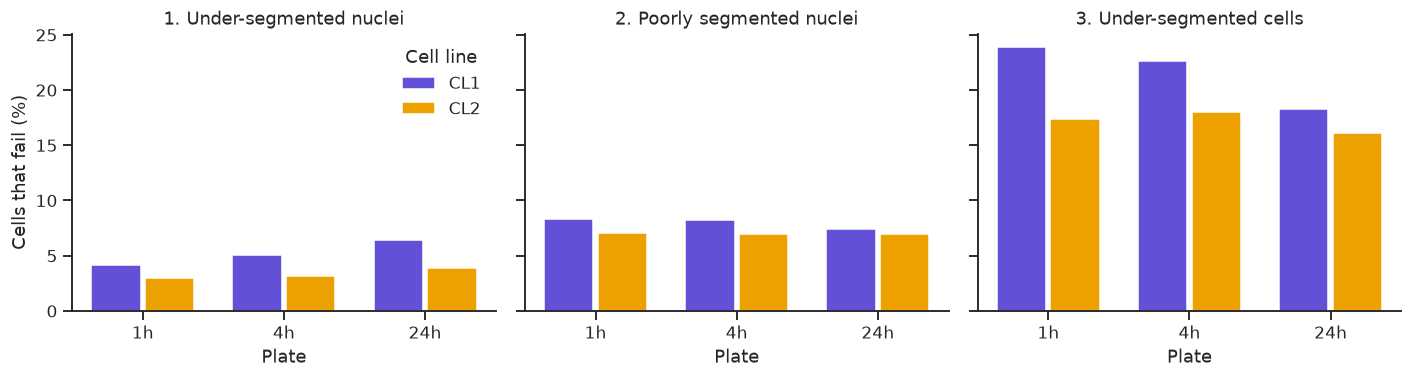

In [5]:
rates = in_time_order(
    cells.group_by("plate", "cell_line").agg(pl.len().alias("cells"), *[(pl.col(name).mean() * 100).round(1) for name in [*condition_names, "failed_qc"]])
)
print(rates)

overlap = (
    cells.with_columns(pl.sum_horizontal(condition_names).alias("n_failed"))
    .group_by("cell_line", "n_failed")
    .len()
    .with_columns((100 * pl.col("len") / pl.col("len").sum().over("cell_line")).round(1).alias("percent"))
    .sort("cell_line", "n_failed")
)
print(overlap)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
width = 0.38
for ax, name in zip(axes, condition_names):
    for offset, line in zip((-width / 2, width / 2), line_order):
        values = [rates.filter((pl.col("plate") == time) & (pl.col("cell_line") == line))[name].item() for time in plate_order]
        ax.bar(np.arange(3) + offset, values, width * 0.92, color=line_colors[line], label=line)
    ax.set(title=condition_titles[name], xticks=range(3), xticklabels=plate_order, xlabel="Plate")
axes[0].set_ylabel("Cells that fail (%)")
axes[0].legend(frameon=False, title="Cell line")
plt.tight_layout()
plt.show()

**What we found**

**In the expected range, but this result alone proves little.**

- 21.9 to 31.0% of cells fail in each plate and cell line. This is inside the range of the paper.
- Condition 3 fails the most cells, 16 to 24%. Condition 1 fails 3 to 6%, and condition 2 fails 7 to 8%.
- Most failed cells fail only one condition. 6.0% of CL1 cells and 4.5% of CL2 cells fail two or three conditions.
- We did not see more failures in crowded wells. The 24h CL2 group has the most cells (1.14 million), and it has the lowest failure rate (21.9%).

The last point is a warning. A z-score limit depends on the average of the group. So a similar share of cells may fail in good data and in bad data. A failure rate alone may not show the quality of the data.

## 4. Where do the DNA limits sit?

**What we check:** the position of the DNA limits, compared with the two normal DNA peaks.

**Why it matters:** this is the most important check in this notebook. Conditions 1 and 3 mark cells with a high DNA signal. But a healthy cell in G2 phase also has twice the DNA of a cell in G1 phase. If the limit sits below 2 times the first peak, the rule marks healthy cells as bad outlines.

A z-score limit also moves with the data. Notebook 01 found that many objects in our profiles are pieces of nuclei, with little DNA. These pieces pull the average down. So the limit may sit lower than it should.

**What good looks like:** the DNA limit of condition 1 sits above the second peak, at more than 2 times the first peak.

shape: (6, 5)
┌───────┬───────────┬───────────────────────┬─────────────────────────────────┬─────────────────────────────────┐
│ plate ┆ cell_line ┆ average_vs_first_peak ┆ condition_1_limit_vs_first_peak ┆ condition_3_limit_vs_first_peak │
│ ---   ┆ ---       ┆ ---                   ┆ ---                             ┆ ---                             │
│ str   ┆ str       ┆ f64                   ┆ f64                             ┆ f64                             │
╞═══════╪═══════════╪═══════════════════════╪═════════════════════════════════╪═════════════════════════════════╡
│ 1h    ┆ CL1       ┆ 1.33                  ┆ 2.48                            ┆ 1.77                            │
│ 1h    ┆ CL2       ┆ 0.83                  ┆ 1.55                            ┆ 1.21                            │
│ 4h    ┆ CL1       ┆ 1.42                  ┆ 2.69                            ┆ 1.88                            │
│ 4h    ┆ CL2       ┆ 0.8                   ┆ 1.54                        

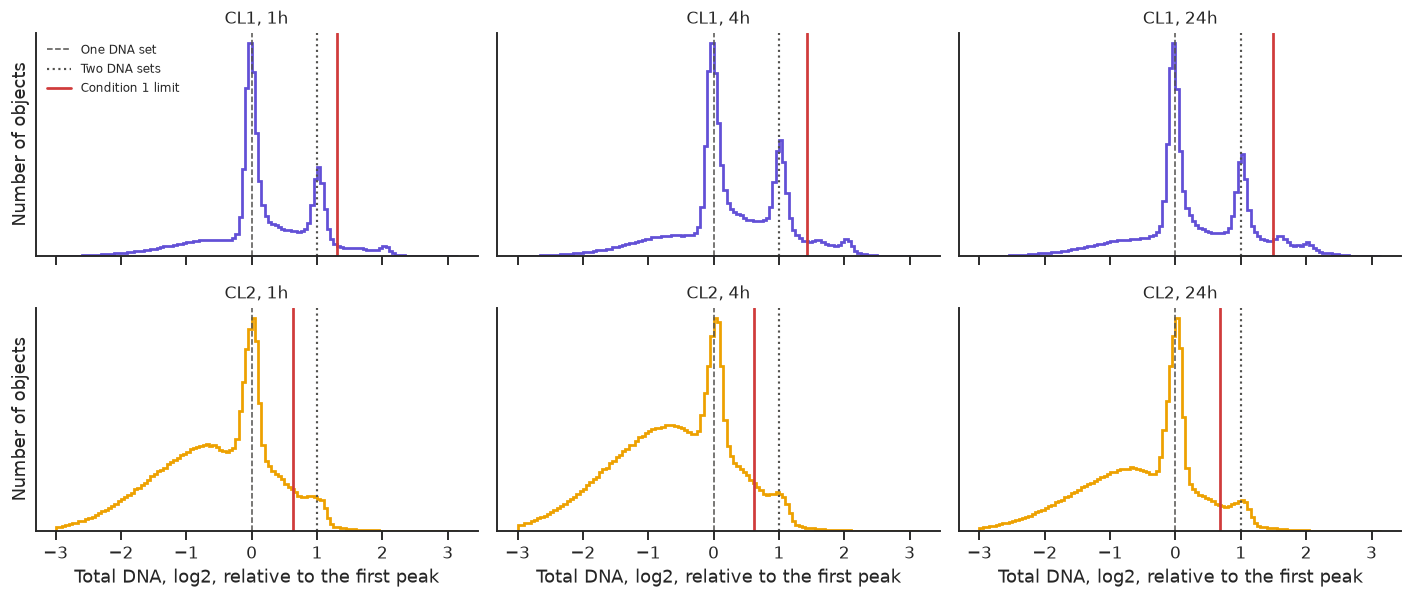

In [6]:
def first_peak(values):
    """Position of the tallest peak of the DNA signal, on a log2 scale (the same as notebook 01)."""
    counts, bin_edges = np.histogram(values, bins=120, range=(5, 12))
    smooth = ndi.gaussian_filter1d(counts.astype(float), 1.5)
    return bin_edges[np.argmax(smooth)] + (bin_edges[1] - bin_edges[0]) / 2


rows = []
for time in plate_order:
    for line in line_order:
        group = cells.filter((pl.col("plate") == time) & (pl.col("cell_line") == line))
        peak = 2 ** first_peak(np.log2(group[nucleus_dna].to_numpy()))
        cell_peak = 2 ** first_peak(np.log2(group[cell_dna].to_numpy()))
        rows.append(
            {
                "plate": time,
                "cell_line": line,
                "first_peak": peak,
                "first_peak_cell": cell_peak,
                "average_dna": group[nucleus_dna].mean(),
                "average_vs_first_peak": group[nucleus_dna].mean() / peak,
                "condition_1_limit_vs_first_peak": (group[nucleus_dna].mean() + 1.5 * group[nucleus_dna].std(ddof=0)) / peak,
                "condition_3_limit_vs_first_peak": (group[cell_dna].mean() + 0.5 * group[cell_dna].std(ddof=0)) / cell_peak,
            }
        )
peaks = pl.DataFrame(rows)
print(peaks.select("plate", "cell_line", pl.col("^.*vs_first_peak$").round(2)))

cells = cells.join(peaks.select("plate", "cell_line", "first_peak"), on=["plate", "cell_line"]).with_columns(
    (pl.col(nucleus_dna) / pl.col("first_peak")).alias("dna_vs_first_peak")
)

fig, axes = plt.subplots(2, 3, figsize=(13, 5.6), sharex=True)
bins = np.arange(-3, 3.2, 0.05)
for row, line in enumerate(line_order):
    for column, time in enumerate(plate_order):
        ax = axes[row, column]
        values = np.log2(cells.filter((pl.col("plate") == time) & (pl.col("cell_line") == line))["dna_vs_first_peak"].to_numpy())
        limit = peaks.filter((pl.col("plate") == time) & (pl.col("cell_line") == line))["condition_1_limit_vs_first_peak"].item()
        ax.hist(values, bins=bins, histtype="step", lw=1.8, color=line_colors[line])
        ax.axvline(0, color=guide_color, ls="--", lw=1, label="One DNA set")
        ax.axvline(1, color=guide_color, ls=":", lw=1.4, label="Two DNA sets")
        ax.axvline(np.log2(limit), color=limit_color, lw=1.8, label="Condition 1 limit")
        ax.set_title(f"{line}, {time}", fontsize=11)
        ax.set_yticks([])
axes[0, 0].legend(frameon=False, fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("Total DNA, log2, relative to the first peak")
for ax in axes[:, 0]:
    ax.set_ylabel("Number of objects")
plt.tight_layout()
plt.show()

**What we found**

**Fail for CL2. This result explains most of this notebook.**

- **In CL2, the condition 1 limit sits below the second peak.** It sits at 1.54 to 1.60 times the first peak, and the second peak sits at 2 times.
- **In CL1, the limit sits above the second peak,** at 2.48 to 2.81 times the first peak.
- **The condition 3 limit sits lower.** It sits at 1.15 to 1.22 times the first peak in CL2. It sits at 1.77 to 2.03 times in CL1.

The cause is visible in the figure. The CL2 curve has a wide shoulder of low-DNA objects on the left. These objects pull the CL2 average down to 0.80 to 0.85 times the first peak. In CL1, the average sits at 1.33 to 1.44 times the first peak. So one rule gives two different limits in the two cell lines. The rule did not change. The damage in the data did.

## 5. Which DNA groups fail?

**What we check:** the share of cells that fail, for each DNA group.

**Why it matters:** a good rule fails the bad objects and keeps the healthy cells. We expect these DNA groups to hold different kinds of objects:

| DNA group | DNA, relative to the first peak | What it likely holds |
|---|---|---|
| Too little | Below 0.7 | Pieces of cut nuclei, and debris |
| First peak | 0.8 to 1.25 | Healthy G1 cells |
| Second peak | 1.6 to 2.5 | Healthy G2 cells |
| Too much | Above 2.8 | Merged nuclei. A healthy nucleus should not hold this much DNA. |

**What good looks like:** few cells fail in the first and second peaks. Most objects fail in the "too little" and "too much" groups.

In [7]:
cells = cells.with_columns(
    pl.when(pl.col("dna_vs_first_peak") < 0.7)
    .then(pl.lit("1 too little"))
    .when(pl.col("dna_vs_first_peak").is_between(0.8, 1.25))
    .then(pl.lit("2 first peak"))
    .when(pl.col("dna_vs_first_peak").is_between(1.6, 2.5))
    .then(pl.lit("3 second peak"))
    .when(pl.col("dna_vs_first_peak") > 2.8)
    .then(pl.lit("4 too much"))
    .otherwise(pl.lit("between groups"))
    .alias("dna_group")
)
dna_groups = in_time_order(
    cells.filter(pl.col("dna_group") != "between groups")
    .group_by("cell_line", "plate", "dna_group")
    .agg((100 * pl.col("failed_qc").mean()).round(1).alias("failed"))
    .pivot(on="dna_group", index=["cell_line", "plate"], values="failed", sort_columns=True)
)
print("Share of cells that fail QC (%)")
print(dna_groups)

shares = in_time_order(
    cells.group_by("cell_line", "plate", "dna_group")
    .len()
    .with_columns((100 * pl.col("len") / pl.col("len").sum().over("cell_line", "plate")).round(1).alias("percent"))
    .pivot(on="dna_group", index=["cell_line", "plate"], values="percent", sort_columns=True)
)
print("Share of all cells in each DNA group (%)")
print(shares)

# which condition fails the cells of the second peak?
second_peak = in_time_order(
    cells.filter(pl.col("dna_group") == "3 second peak")
    .group_by("cell_line", "plate")
    .agg(pl.len().alias("cells"), *[(pl.col(name).mean() * 100).round(1) for name in condition_names])
)
print("Cells in the second peak: share that fail each condition (%)")
print(second_peak)

Share of cells that fail QC (%)
shape: (6, 6)
┌───────────┬───────┬──────────────┬──────────────┬───────────────┬────────────┐
│ cell_line ┆ plate ┆ 1 too little ┆ 2 first peak ┆ 3 second peak ┆ 4 too much │
│ ---       ┆ ---   ┆ ---          ┆ ---          ┆ ---           ┆ ---        │
│ str       ┆ str   ┆ f64          ┆ f64          ┆ f64           ┆ f64        │
╞═══════════╪═══════╪══════════════╪══════════════╪═══════════════╪════════════╡
│ CL1       ┆ 1h    ┆ 20.8         ┆ 4.9          ┆ 79.7          ┆ 100.0      │
│ CL1       ┆ 4h    ┆ 18.8         ┆ 5.5          ┆ 57.8          ┆ 100.0      │
│ CL1       ┆ 24h   ┆ 15.2         ┆ 4.5          ┆ 34.2          ┆ 100.0      │
│ CL2       ┆ 1h    ┆ 9.1          ┆ 11.3         ┆ 100.0         ┆ 100.0      │
│ CL2       ┆ 4h    ┆ 8.5          ┆ 15.9         ┆ 100.0         ┆ 100.0      │
│ CL2       ┆ 24h   ┆ 9.8          ┆ 8.2          ┆ 100.0         ┆ 100.0      │
└───────────┴───────┴──────────────┴──────────────┴────────────

**What we found**

**Fail. The rule fails the wrong DNA groups.**

- **Too little DNA:** only 8.5 to 20.8% of these objects fail. These objects are likely pieces and debris, so most of them stay.
- **First peak:** 4.5 to 15.9% fail. This is low, as we hoped.
- **Second peak:** 100% fail in CL2, and 34.2 to 79.7% fail in CL1.
- **Too much DNA:** 100% fail. This is correct, because a healthy nucleus should not hold this much DNA.

The third table shows the cause. **Condition 3 fails 100% of the CL2 second peak, and 30.6 to 78.0% of the CL1 second peak.** Condition 2 fails only 4.2 to 5.5% of it. Condition 1 fails 0 to 0.3% in CL1 and 34.5 to 43.0% in CL2.

The second peak can hold two kinds of objects. One is a healthy G2 cell. The other is two G1 nuclei merged into one outline, because two G1 nuclei hold the same DNA as one G2 nucleus. A DNA limit cannot separate these two kinds of objects. Section 7 looks at them by eye.

## 6. Does coSMicQC find the cut nuclei?

**What we check:** the share of cut nuclei that fail QC. Notebook 01 found these pieces in 72 control images, with a shape test on the masks.

**Why it matters:** cut nuclei are the largest problem in these profiles. Condition 2 looks for them. This check uses a separate answer, so it does not depend on the DNA groups above.

**What good looks like:** most pieces of cut nuclei fail QC, and few nuclei that were not cut fail.

In [8]:
objects_path = qc_cache_dir / "nuclei_objects.parquet"
groups_path = qc_cache_dir / "nuclei_groups.parquet"
if objects_path.exists() and groups_path.exists():
    # notebook 01 did not save object numbers, so we match its objects by image and exact area
    groups = pl.read_parquet(groups_path).with_columns(((pl.col("n_objects") > 1) & (pl.col("solidity") >= 0.9)).alias("is_cut_piece"))
    objects = (
        pl.read_parquet(objects_path)
        .join(groups.select("plate", "site", "group", "is_cut_piece"), on=["plate", "site", "group"])
        .rename({"site": "Metadata_Acquisition", "area": "Nuclei_AreaShape_Area", "dna": "dna_01"})
    )
    match_on = ["plate", "Metadata_Acquisition", "Nuclei_AreaShape_Area"]
    matched = (
        objects.filter(~pl.struct(match_on).is_duplicated())
        .join(cells.filter(~pl.struct(match_on).is_duplicated()), on=match_on)
        .filter((pl.col("dna_01") / pl.col(nucleus_dna) - 1).abs() < 0.05)
    )
    print(f"Matched {matched.height:,} of {objects.height:,} objects from notebook 01")
    print(
        matched.group_by("cell_line", "is_cut_piece")
        .agg(
            pl.len().alias("objects"),
            *[(pl.col(name).mean() * 100).round(1) for name in [*condition_names, "failed_qc"]],
        )
        .sort("cell_line", "is_cut_piece")
    )
else:
    print("Notebook 01 saved no cut nuclei for these profiles. Run it first to get this check.")

Matched 25,541 of 33,617 objects from notebook 01
shape: (4, 7)
┌───────────┬──────────────┬─────────┬────────────────────────┬─────────────────────────┬───────────────────────┬───────────┐
│ cell_line ┆ is_cut_piece ┆ objects ┆ under_segmented_nuclei ┆ poorly_segmented_nuclei ┆ under_segmented_cells ┆ failed_qc │
│ ---       ┆ ---          ┆ ---     ┆ ---                    ┆ ---                     ┆ ---                   ┆ ---       │
│ str       ┆ bool         ┆ u32     ┆ f64                    ┆ f64                     ┆ f64                   ┆ f64       │
╞═══════════╪══════════════╪═════════╪════════════════════════╪═════════════════════════╪═══════════════════════╪═══════════╡
│ CL1       ┆ false        ┆ 8109    ┆ 6.0                    ┆ 5.1                     ┆ 26.7                  ┆ 30.4      │
│ CL1       ┆ true         ┆ 2306    ┆ 3.5                    ┆ 15.4                    ┆ 13.2                  ┆ 26.5      │
│ CL2       ┆ false        ┆ 7741    ┆ 4.5            

**What we found**

**Fail. coSMicQC does not find most cut nuclei.**

We matched 25,541 of the 33,617 objects from notebook 01. The match uses the image, the exact area and the DNA signal.

- Pieces of cut nuclei fail **less** often than other nuclei. In CL1, 26.5% of pieces fail, and 30.4% of other nuclei fail. In CL2, 18.4% of pieces fail, and 26.7% of other nuclei fail.
- Condition 2 does what it should, but it finds few pieces. It fails 15.4% of pieces in CL1 and 8.8% in CL2. It fails 5.1% of other nuclei in both cell lines.

A possible reason is that a piece can have a smooth outline and a low DNA signal. Then it can look like a small healthy nucleus to these rules.

## 7. Do the marked cells look wrong?

**What we check:** random cells from each group, with the outlines drawn on the DNA image.

**Why it matters:** the authors of coSMicQC set their limits by eye, while they looked at single cells. Numbers alone cannot show whether a marked cell has a bad outline.

**What good looks like:** the marked cells have wrong outlines, and the passing cells have correct outlines.

Each picture shows 160 by 160 pixels. Yellow is the nucleus outline. Magenta is the cell outline. We use only control wells, because they have no treatment.

/tmp/ipykernel_1017197/387803276.py:44: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


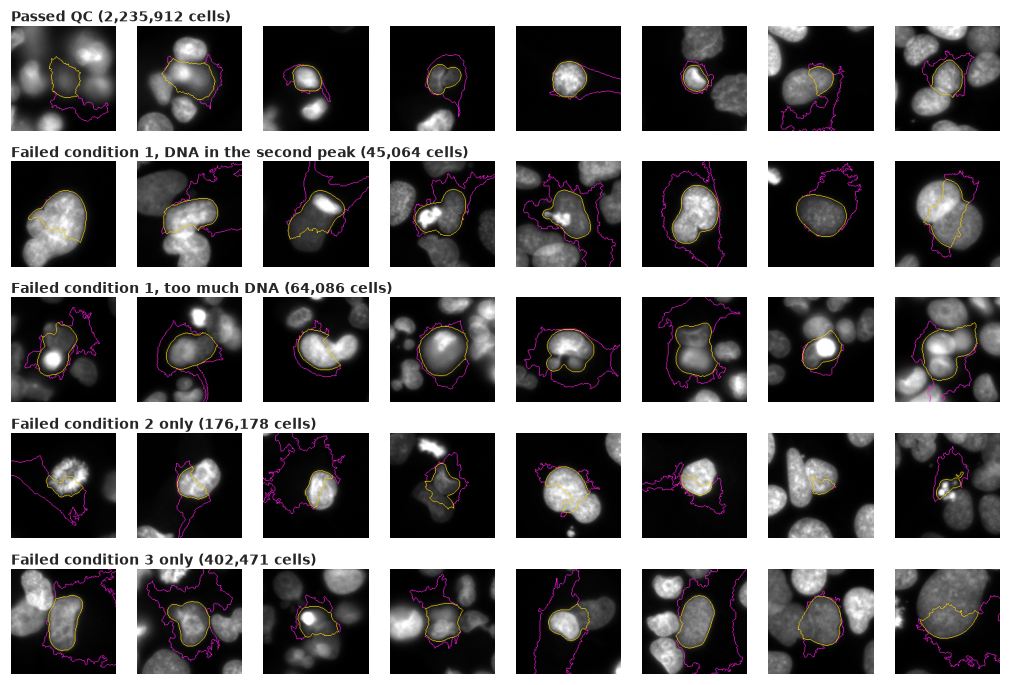

In [9]:
def plate_masks(time):
    """Folder with the masks of one plate."""
    plate = plate_names[time]
    run_dir = pathlib.Path((results_dir / plate / "DONE").read_text().strip())
    return run_dir / "masks" / plate


def read_tiff(path):
    """Read one TIFF file as an array."""
    return np.array(Image.open(path)).astype(float)


def edge_of(mask):
    """Pixels on the edge of one object."""
    return mask & ~ndi.binary_erosion(mask, iterations=1, border_value=1)


def show_examples(groups, n_columns=8, half=80):
    """Draw random cells from each named group: one row per group."""
    fig, axes = plt.subplots(len(groups), n_columns, figsize=(1.45 * n_columns, 1.55 * len(groups)))
    for row, (title, selection) in enumerate(groups.items()):
        picks = selection.sample(n=min(n_columns, selection.height), seed=seed)
        for column in range(n_columns):
            ax = axes[row, column]
            ax.axis("off")
            if column == 0:
                ax.text(0, 1.04, f"{title} ({selection.height:,} cells)", transform=ax.transAxes, fontsize=9, fontweight="bold")
            if column >= picks.height:
                continue
            cell = picks.row(column, named=True)
            time, site, number = cell["plate"], cell["Metadata_Acquisition"], cell["Metadata_ObjectNumber"]
            dna = read_tiff(images_dir / plate_names[time] / f"{site}_Fluorescence_405_nm_Ex.tiff")
            nuclei = read_tiff(plate_masks(time) / f"{site}_Nuclei.tiff")
            whole_cells = read_tiff(plate_masks(time) / f"{site}_Cells.tiff")
            y = int(np.clip(cell["Nuclei_Location_Center_Y"], half, dna.shape[0] - half))
            x = int(np.clip(cell["Nuclei_Location_Center_X"], half, dna.shape[1] - half))
            window = (slice(y - half, y + half), slice(x - half, x + half))
            low, high = np.percentile(dna[window], [1, 99.8])
            gray = np.clip((dna[window] - low) / (high - low), 0, 1)
            rgb = np.dstack([gray] * 3)
            rgb[edge_of(whole_cells[window] == number)] = (1, 0.1, 0.9)
            rgb[edge_of(nuclei[window] == number)] = (1, 0.85, 0)
            ax.imshow(rgb)
    plt.tight_layout()
    plt.show()


control = cells.filter(pl.col("well_type") == "control")
only_one = pl.sum_horizontal(condition_names) == 1
show_examples(
    {
        "Passed QC": control.filter(~pl.col("failed_qc")),
        "Failed condition 1, DNA in the second peak": control.filter(pl.col("under_segmented_nuclei") & (pl.col("dna_group") == "3 second peak")),
        "Failed condition 1, too much DNA": control.filter(pl.col("under_segmented_nuclei") & (pl.col("dna_group") == "4 too much")),
        "Failed condition 2 only": control.filter(pl.col("poorly_segmented_nuclei") & only_one),
        "Failed condition 3 only": control.filter(pl.col("under_segmented_cells") & only_one),
    }
)

**What we found**

**Mixed. This is a small sample of 8 cells per row, so these are first impressions.**

- **Passed QC:** most nuclei have one clean outline. At least one nucleus in this row looks cut, so bad outlines can pass. Many cell outlines look ragged, and these rules do not test that.
- **Failed condition 1, DNA in the second peak:** most of these outlines appear to hold two touching nuclei. So this condition may find real problems, even in the second peak.
- **Failed condition 1, too much DNA:** most outlines appear to hold merged nuclei or very bright nuclei. This condition looks useful.
- **Failed condition 2 only:** many nuclei show cut lines or odd shapes. This condition looks useful, but section 6 shows that it finds few of the cut nuclei.
- **Failed condition 3 only:** most of these cells have one normal nucleus with a clean outline. **These cells look like false alarms.** Condition 3 is the largest condition, so this is the main problem.

## 8. What happens to the DNA peaks if we remove the failed cells?

**What we check:** the DNA curve of all objects, and the DNA curve of the objects that pass QC.

**Why it matters:** the two DNA peaks are our control for segmentation. Good QC should remove the low shoulder of pieces and keep both peaks.

**What good looks like:** the low shoulder shrinks, and the second peak stays.

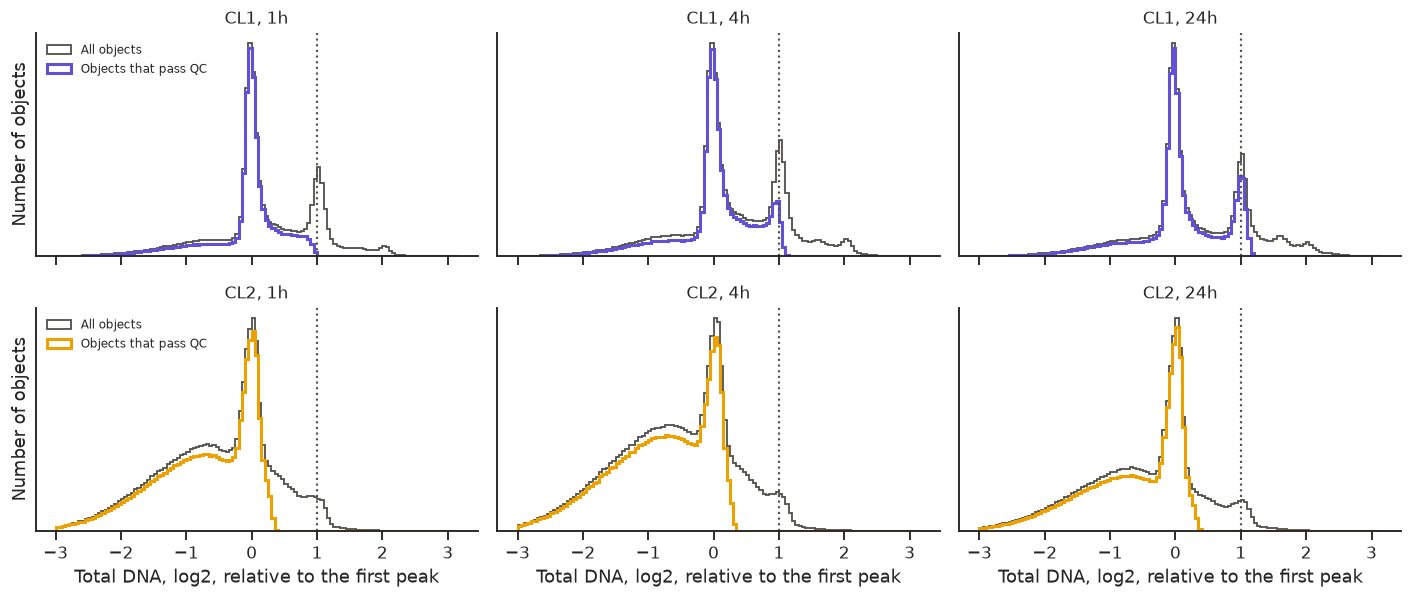

shape: (6, 6)
┌───────────┬───────┬───────────────────────┬──────────────────────┬────────────────────┬───────────────────┐
│ cell_line ┆ plate ┆ too_little_dna_before ┆ too_little_dna_after ┆ second_peak_before ┆ second_peak_after │
│ ---       ┆ ---   ┆ ---                   ┆ ---                  ┆ ---                ┆ ---               │
│ str       ┆ str   ┆ f64                   ┆ f64                  ┆ f64                ┆ f64               │
╞═══════════╪═══════╪═══════════════════════╪══════════════════════╪════════════════════╪═══════════════════╡
│ CL1       ┆ 1h    ┆ 14.6                  ┆ 16.7                 ┆ 22.2               ┆ 6.5               │
│ CL1       ┆ 4h    ┆ 14.2                  ┆ 16.3                 ┆ 24.3               ┆ 14.5              │
│ CL1       ┆ 24h   ┆ 13.9                  ┆ 15.5                 ┆ 22.9               ┆ 19.8              │
│ CL2       ┆ 1h    ┆ 45.6                  ┆ 53.9                 ┆ 6.9                ┆ 0.0             

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5.6), sharex=True)
for row, line in enumerate(line_order):
    for column, time in enumerate(plate_order):
        ax = axes[row, column]
        group = cells.filter((pl.col("plate") == time) & (pl.col("cell_line") == line))
        before = np.log2(group["dna_vs_first_peak"].to_numpy())
        after = np.log2(group.filter(~pl.col("failed_qc"))["dna_vs_first_peak"].to_numpy())
        ax.hist(before, bins=bins, histtype="step", lw=1.2, color=guide_color, label="All objects")
        ax.hist(after, bins=bins, histtype="step", lw=2, color=line_colors[line], label="Objects that pass QC")
        ax.axvline(1, color=guide_color, ls=":", lw=1.4)
        ax.set_title(f"{line}, {time}", fontsize=11)
        ax.set_yticks([])
        if column == 0:
            ax.legend(frameon=False, fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("Total DNA, log2, relative to the first peak")
for ax in axes[:, 0]:
    ax.set_ylabel("Number of objects")
plt.tight_layout()
plt.show()

print(
    in_time_order(cells.group_by("cell_line", "plate").agg(
        (100 * (pl.col("dna_vs_first_peak") < 0.7).mean()).round(1).alias("too_little_dna_before"),
        (100 * (pl.col("dna_vs_first_peak") < 0.7).filter(~pl.col("failed_qc")).mean()).round(1).alias("too_little_dna_after"),
        (100 * pl.col("dna_vs_first_peak").is_between(1.6, 2.5).mean()).round(1).alias("second_peak_before"),
        (100 * pl.col("dna_vs_first_peak").is_between(1.6, 2.5).filter(~pl.col("failed_qc")).mean()).round(1).alias("second_peak_after"),
    ))
)

**What we found**

**Fail. The data get worse, not better, if we remove the failed cells.**

- **The second peak disappears in CL2.** Its share falls from 6.5 to 7.3% of objects to 0.0%.
- **The second peak shrinks in CL1.** Its share falls from 22.2 to 6.5% at 1h, from 24.3 to 14.5% at 4h, and from 22.9 to 19.8% at 24h.
- **The share of low-DNA objects rises.** In CL2, it rises from 42.6 to 49.4% before QC, to 49.3 to 59.2% after QC.

A filter with these limits would remove most cells that copied their DNA. This could also bias any result that depends on the cell cycle.

## 9. Do our choices change the result?

**What we check:** the same rules with two other choices. One uses the numbers printed in panel A of Figure 2. The other uses z-scores over the whole plate, as the authors did.

**Why it matters:** we chose 1.5 and -1.6, and we chose one group per plate and cell line. The reader should see what these choices change.

**What good looks like:** the main result stays the same with all three choices.

In [11]:
versions = {
    "1.5 and -1.6, per cell line": None,
    "1.15 and -1.16, per cell line": flag_cells(cells.select(columns + ["row_id", "plate", "cell_line"]), conditions_panel_a, ["plate", "cell_line"]),
    "1.5 and -1.6, whole plate": flag_cells(cells.select(columns + ["row_id", "plate", "cell_line"]), conditions, ["plate"]),
}
extra = cells.select("row_id", "dna_group")
rows = []
for version, table in versions.items():
    table = cells if table is None else table.join(extra, on="row_id")
    summary = table.group_by("cell_line").agg(
        *[(pl.col(name).mean() * 100).round(1) for name in [*condition_names, "failed_qc"]],
        (100 * pl.col("failed_qc").filter(pl.col("dna_group") == "1 too little").mean()).round(1).alias("too_little_dna_failed"),
        (100 * pl.col("failed_qc").filter(pl.col("dna_group") == "3 second peak").mean()).round(1).alias("second_peak_failed"),
    )
    rows.append(summary.with_columns(pl.lit(version).alias("version")))
print(pl.concat(rows).select("version", pl.exclude("version")).sort("cell_line", "version"))

shape: (6, 8)
┌─────────────────────────┬───────────┬────────────────────────┬────────────────────────┬───────────────────────┬───────────┬───────────────────────┬────────────────────┐
│ version                 ┆ cell_line ┆ under_segmented_nuclei ┆ poorly_segmented_nucle ┆ under_segmented_cells ┆ failed_qc ┆ too_little_dna_failed ┆ second_peak_failed │
│ ---                     ┆ ---       ┆ ---                    ┆ i                      ┆ ---                   ┆ ---       ┆ ---                   ┆ ---                │
│ str                     ┆ str       ┆ f64                    ┆ ---                    ┆ f64                   ┆ f64       ┆ f64                   ┆ f64                │
│                         ┆           ┆                        ┆ f64                    ┆                       ┆           ┆                       ┆                    │
╞═════════════════════════╪═══════════╪════════════════════════╪════════════════════════╪═══════════════════════╪═══════════╪══════

**What we found**

**The main result stays the same with all three choices.** All three versions fail 100% of the CL2 second peak.

- **The numbers in panel A** fail more cells: 31.9% against 28.1% in CL1, and 27.0% against 22.8% in CL2. They catch more low-DNA objects (28.6% against 18.3% in CL1), but most low-DNA objects still pass. The rate of healthy-looking failures does not improve.
- **Whole-plate z-scores** give similar totals. However, condition 2 then fails 5.3% of CL1 and 8.8% of CL2, because CL2 nuclei are normally less smooth. With one group per cell line, the rates are 8.0% and 7.1%. This supports our choice of separate groups.

## 10. Does QC remove some treatments more than others?

**What we check:** the share of failed cells by well type, by plate edge, and for each treatment.

**Why it matters:** if one treatment fails much more often than DMSO, then QC may remove the effect that we want to measure. A treatment can change the shape of a nucleus or the amount of DNA.

**What good looks like:** failure rates are close to the DMSO control wells.

In [12]:
print(
    cells.group_by("cell_line", "well_type", "edge")
    .agg(pl.len().alias("cells"), pl.col("Metadata_Well").n_unique().alias("wells"), (100 * pl.col("failed_qc").mean()).round(1).alias("failed"))
    .sort("cell_line", "well_type", "edge")
)

# compare each treatment with the control wells of the same plate and cell line
treatments = (
    cells.group_by("plate", "cell_line", "treatment", "well_type")
    .agg(pl.len().alias("cells"), (100 * pl.col("failed_qc").mean()).alias("failed"))
    .filter(pl.col("cells") >= 500)
)
baseline = (
    cells.filter(pl.col("well_type") == "control")
    .group_by("plate", "cell_line")
    .agg((100 * pl.col("failed_qc").mean()).alias("control_failed"))
)
difference = (
    treatments.filter(pl.col("well_type") != "control")
    .join(baseline, on=["plate", "cell_line"])
    .with_columns((pl.col("failed") - pl.col("control_failed")).alias("difference"))
)
print(difference.select(pl.col("difference").abs().median().round(1).alias("median_size"), pl.col("difference").abs().max().round(1).alias("largest_size")))
print(difference.with_columns(pl.col("difference").abs().alias("size")).sort("size", descending=True).head(8).select("plate", "cell_line", "treatment", "well_type", "cells", pl.col("failed").round(1), pl.col("control_failed").round(1), pl.col("difference").round(1)))

shape: (12, 6)
┌───────────┬───────────┬───────┬─────────┬───────┬────────┐
│ cell_line ┆ well_type ┆ edge  ┆ cells   ┆ wells ┆ failed │
│ ---       ┆ ---       ┆ ---   ┆ ---     ┆ ---   ┆ ---    │
│ str       ┆ str       ┆ bool  ┆ u32     ┆ u32   ┆ f64    │
╞═══════════╪═══════════╪═══════╪═════════╪═══════╪════════╡
│ CL1       ┆ compound  ┆ false ┆ 339367  ┆ 37    ┆ 29.1   │
│ CL1       ┆ compound  ┆ true  ┆ 84947   ┆ 8     ┆ 27.6   │
│ CL1       ┆ control   ┆ false ┆ 997036  ┆ 105   ┆ 28.1   │
│ CL1       ┆ control   ┆ true  ┆ 236490  ┆ 22    ┆ 26.7   │
│ CL1       ┆ ligand    ┆ false ┆ 106752  ┆ 12    ┆ 28.8   │
│ CL1       ┆ ligand    ┆ true  ┆ 62733   ┆ 6     ┆ 28.9   │
│ CL2       ┆ compound  ┆ false ┆ 494909  ┆ 38    ┆ 24.9   │
│ CL2       ┆ compound  ┆ true  ┆ 86828   ┆ 7     ┆ 25.0   │
│ CL2       ┆ control   ┆ false ┆ 1438248 ┆ 105   ┆ 22.0   │
│ CL2       ┆ control   ┆ true  ┆ 289686  ┆ 22    ┆ 22.9   │
│ CL2       ┆ ligand    ┆ false ┆ 151160  ┆ 11    ┆ 21.8   │
│ CL2    

shape: (1, 2)
┌─────────────┬──────────────┐
│ median_size ┆ largest_size │
│ ---         ┆ ---          │
│ f64         ┆ f64          │
╞═════════════╪══════════════╡
│ 0.6         ┆ 24.3         │
└─────────────┴──────────────┘
shape: (8, 8)
┌───────┬───────────┬───────────┬───────────┬───────┬────────┬────────────────┬────────────┐
│ plate ┆ cell_line ┆ treatment ┆ well_type ┆ cells ┆ failed ┆ control_failed ┆ difference │
│ ---   ┆ ---       ┆ ---       ┆ ---       ┆ ---   ┆ ---    ┆ ---            ┆ ---        │
│ str   ┆ str       ┆ str       ┆ str       ┆ u32   ┆ f64    ┆ f64            ┆ f64        │
╞═══════╪═══════════╪═══════════╪═══════════╪═══════╪════════╪════════════════╪════════════╡
│ 24h   ┆ CL2       ┆ CBK600005 ┆ compound  ┆ 34633 ┆ 45.2   ┆ 21.0           ┆ 24.3       │
│ 24h   ┆ CL1       ┆ CBK600005 ┆ compound  ┆ 12600 ┆ 34.1   ┆ 23.4           ┆ 10.6       │
│ 4h    ┆ CL2       ┆ CBK600005 ┆ compound  ┆ 34197 ┆ 32.7   ┆ 23.3           ┆ 9.4        │
│ 24h   ┆ C

**What we found**

**Mostly pass, with one clear exception.**

- Well type and plate edge change the failure rate by about 3 percentage points or less in each cell line.
- The typical treatment differs from the control wells by only 0.6 points.
- **CBK600005 is the exception.** At 24h in CL2, 45.2% of its cells fail, and 21.0% of control cells fail. It also differs from control in CL1 at 24h (10.6 points) and in CL2 at 4h (9.4 points).
- TGFb1 in CL1 at 24h fails 8.1 points more often than control. TGFb1 is the positive control for biology in notebook 01.

A high failure rate for a treatment may be a real effect, for example larger or brighter nuclei. If we remove these cells, we may remove the effect that we want to measure. So we must look at these wells before we use any filter.

## 11. Save the marks

We save one file per plate in `data/cosmicqc/`. Each file has one row per cell and these columns:

- `Metadata_Plate`, `Metadata_Well`, `Metadata_Site`, `Metadata_Acquisition` and `Metadata_ObjectNumber`: they identify the cell. They match the profiles.
- `Metadata_cqc_<condition>_is_outlier`: True if the cell failed that condition.
- `Metadata_cqc_failed_qc`: True if the cell failed at least one condition.

The profiles do not change. To use the marks, join a file to its profile on the plate, acquisition and object number columns.

In [13]:
saved = []
for time in plate_order:
    plate_cells = cells.filter(pl.col("plate") == time)
    marks = plate_cells.select(
        "Metadata_Plate",
        "Metadata_Well",
        "Metadata_Site",
        "Metadata_Acquisition",
        "Metadata_ObjectNumber",
        *[pl.col(name).alias(f"Metadata_cqc_{name}_is_outlier") for name in condition_names],
        pl.col("failed_qc").alias("Metadata_cqc_failed_qc"),
    )
    path = output_dir / f"{plate_names[time]}.cqc.parquet"
    marks.write_parquet(path)
    check = pl.scan_parquet(path).select(pl.len()).collect().item()
    if check != pl.scan_parquet(plate_files[time]).select(pl.len()).collect().item():
        raise ValueError(f"{path.name} does not have one row per cell")
    saved.append({"file": path.name, "cells": check, "megabytes": round(path.stat().st_size / 2**20, 1)})
print(pl.DataFrame(saved))

shape: (3, 3)
┌─────────────────────────────────────────────────────┬─────────┬───────────┐
│ file                                                ┆ cells   ┆ megabytes │
│ ---                                                 ┆ ---     ┆ ---       │
│ str                                                 ┆ i64     ┆ f64       │
╞═════════════════════════════════════════════════════╪═════════╪═══════════╡
│ PB100171_Panc1_hPSC_1h_2026-10-03_12.20.40.cqc.par… ┆ 1220826 ┆ 0.5       │
│ PB100172_Panc1_hPSC_4h_2026-10-05_14.52.02.cqc.par… ┆ 1424516 ┆ 0.5       │
│ PB100173_Panc1_hPSC_24h_2026-10-06_12.54.35.cqc.pa… ┆ 1732501 ┆ 0.6       │
└─────────────────────────────────────────────────────┴─────────┴───────────┘


## 12. Decision

### Verdict

**Do not remove cells from these profiles with the marks in this notebook.** Keep the marks as a record, and use them to choose the next test.

| Part of the rule | Status on these profiles | Reason |
|---|---|---|
| Condition 1: under-segmented nuclei | Promising, test again | The examples look correct, but the CL2 limit sits too low |
| Condition 2: poorly segmented nuclei | Promising, test again | The examples look correct, and it fails few second-peak cells, but it misses most cut nuclei |
| Condition 3: under-segmented cells | **Do not use yet** | It fails all CL2 second-peak cells, and the examples look like false alarms |

### What to do next

1. **Finish the new CellProfiler run first.** QC cannot rejoin a cut nucleus, and it cannot restore a nucleus that CellProfiler deleted. Better segmentation must come first.
2. **Run this notebook again on the new profiles.** Replace the files in `data/sc-profiles`, and run notebook 01 again to refresh `data/qc-cache`. Then run `_run-cosmic-qc.sbatch`. With fewer pieces, the average should rise, and the limits should move up. We have not tested this.
3. **Repeat sections 4 to 8.** We need three results before we use the rule. The condition 1 limit must sit above 2 times the first peak in both cell lines. The second peak must stay after QC. The examples must look correct.
4. **If condition 3 still fails healthy cells, test a fixed DNA limit.** One option is 2.8 times the first peak, per plate and cell line, in place of a z-score limit. In this notebook, 0.3 to 8.4% of objects sit above that value. We have not tested this as a QC rule.
5. **Look at the CBK600005 wells** before any filter removes their cells.

The new settings may still leave merged piles of nuclei in the dense CL1 wells at 24h. Conditions 1 and 2 are the best candidates to mark them.

### What this notebook cannot show

- These profiles use the first CellProfiler settings. These results may change with the new settings.
- We do not know the true state of each cell. The DNA groups and the examples are indirect evidence.
- The second peak can hold both healthy G2 cells and two merged G1 nuclei. We did not measure how many of each it holds.
- Section 7 shows only 8 cells per row, from control wells. Section 6 uses only 76% of the objects from 72 control images.
- We did not check how the marks change later results, such as replicate agreement or the effect of TGFβ1.
- The authors used a different dataset and set their limits by eye, and they advise users to check the limits for each plate. So these limits are starting values, not fixed standards.